In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib ucimlrepo xgboost

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import pandas as pd
import numpy as np
import joblib

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

# Load dataset
data = fetch_ucirepo(id=350)

X = data.data.features.copy()
y = data.data.targets.iloc[:, 0]

# Rename columns
columns = [
    'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
    'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
    'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
    'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'
]

X.columns = columns

# Feature engineering
X['TOTAL_BILL'] = X[
    [f'BILL_AMT{i}' for i in range(1, 7)]
].sum(axis=1)

X['TOTAL_PAYMENT'] = X[
    [f'PAY_AMT{i}' for i in range(1, 7)]
].sum(axis=1)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Load saved preprocessing pipeline
preprocessor = joblib.load(
    "../_Feature_Engineering_Preprocessing/preprocessing_pipeline.pkl"
)

# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse data to dense if necessary
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
    X_test_processed = X_test_processed.toarray()

print("Dataset loaded successfully!")
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Dataset loaded successfully!
Training shape: (24000, 35)
Testing shape: (6000, 35)


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42, class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )
}

print("Four models are ready!")

ModuleNotFoundError: No module named 'xgboost'

In [4]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 2.1 MB/s eta 0:00:23
   - -------------------------------------- 1.3/48.9 MB 2.4 MB/s eta 0:00:20
   - -------------------------------------- 1.8/48.9 MB 2.5 MB/s eta 0:00:20
   -- ------------------------------------- 2.9/48.9 MB 2.9 MB/s eta 0:00:17
   -- ------------------------------------- 3.7/48.9 MB 3.1 MB/s eta 0:00:15
   ---- ----------------------------------- 5.0/48.9 MB 3.5 MB/s eta 0:00:13
   ----- ---------------------------------- 6.6/48.9 MB 4.0 MB/s eta 0:00:11
   ------ --------------------------------- 7.9/48.9 MB 4.3 MB/s eta 0:00:10
   ------- -------------------------------- 9.2/48.9 MB 4.5 MB/s eta 0:00:09
   -------- ------------------------------- 10.7/48.9 MB 4.8 MB/s eta 0:00:08
   ---------- ----------------------------- 12.3/48.9 MB 5.0 MB/s eta 0:00:08
   --------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )
}

print("Four models are ready!")

Four models are ready!


In [4]:
import pandas as pd
import joblib

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

# Load dataset
data = fetch_ucirepo(id=350)

X = data.data.features.copy()
y = data.data.targets.iloc[:, 0]

# Rename columns
X.columns = [
    'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
    'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
    'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
    'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'
]

# Feature engineering
X['TOTAL_BILL'] = X[
    [f'BILL_AMT{i}' for i in range(1, 7)]
].sum(axis=1)

X['TOTAL_PAYMENT'] = X[
    [f'PAY_AMT{i}' for i in range(1, 7)]
].sum(axis=1)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Load preprocessing pipeline
preprocessor = joblib.load(
    "../_Feature_Engineering_Preprocessing/preprocessing_pipeline.pkl"
)

# Preprocess data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
    X_test_processed = X_test_processed.toarray()

print("Training data ready!")
print(X_train_processed.shape)

Training data ready!
(24000, 35)


In [5]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

results = []

for name, model in best_models.items():

    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print(results_df)

Empty DataFrame
Columns: []
Index: []


In [7]:
print(best_models.keys())

dict_keys([])


In [8]:
best_models = {}

In [11]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

best_models = {}

for name, model in models.items():

    print("Training:", name)

    grid = GridSearchCV(
        estimator=model,
        param_grid=parameters[name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1
    )

    grid.fit(X_train_processed, y_train)

    best_models[name] = grid.best_estimator_

    print("Best Parameters:", grid.best_params_)
    print("Best ROC-AUC:", grid.best_score_)

print("All models trained successfully!")

Training: Logistic Regression
Best Parameters: {'C': 0.1}
Best ROC-AUC: 0.7274900594423015
Training: Random Forest
Best Parameters: {'max_depth': 10, 'n_estimators': 200}
Best ROC-AUC: 0.780645754623141
Training: Gradient Boosting
Best Parameters: {'learning_rate': 0.1, 'n_estimators': 100}
Best ROC-AUC: 0.7813522045739146
Training: XGBoost
Best Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}
Best ROC-AUC: 0.7831677163788082
All models trained successfully!


In [12]:
print(best_models.keys())

dict_keys(['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost'])


In [13]:
results = []

for name, model in best_models.items():
    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.679500   0.368953  0.632253  0.465982  0.710170
1        Random Forest  0.778333   0.499037  0.585531  0.538835  0.776691
2    Gradient Boosting  0.819333   0.667125  0.365486  0.472249  0.777818
3              XGBoost  0.818667   0.666667  0.360211  0.467710  0.778910


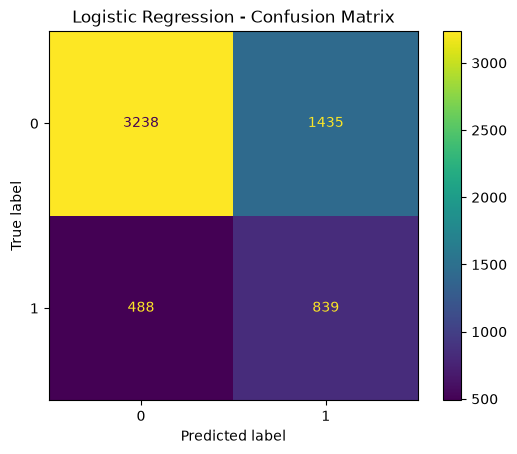

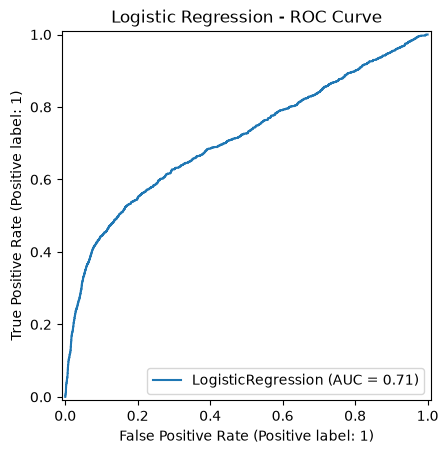

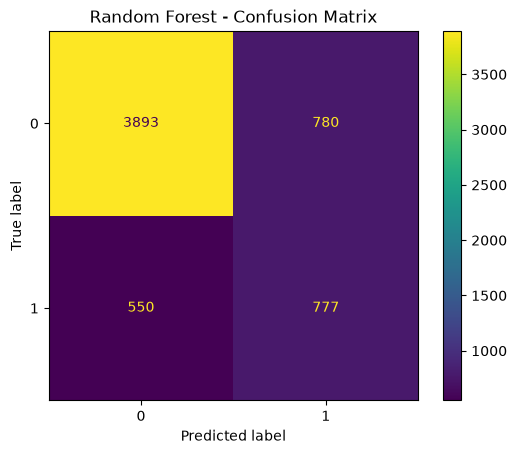

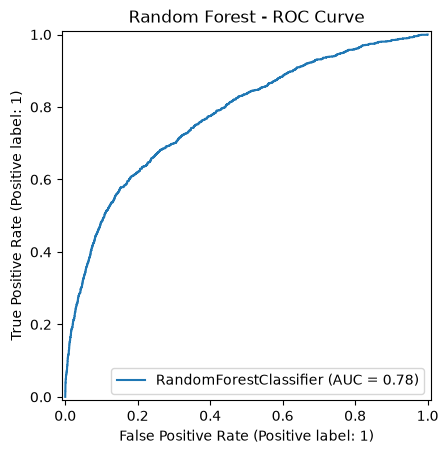

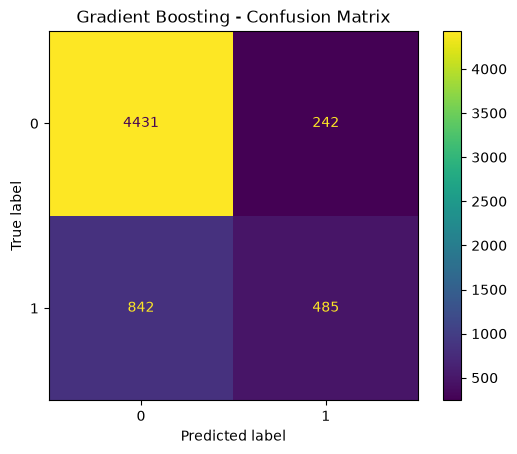

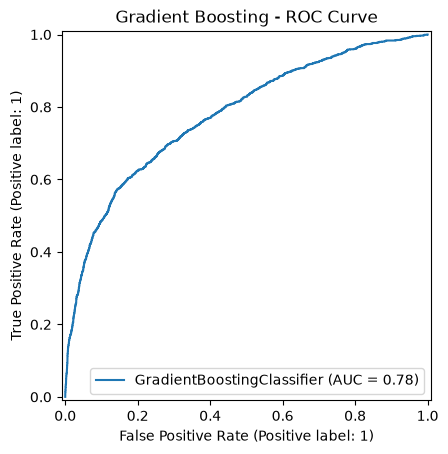

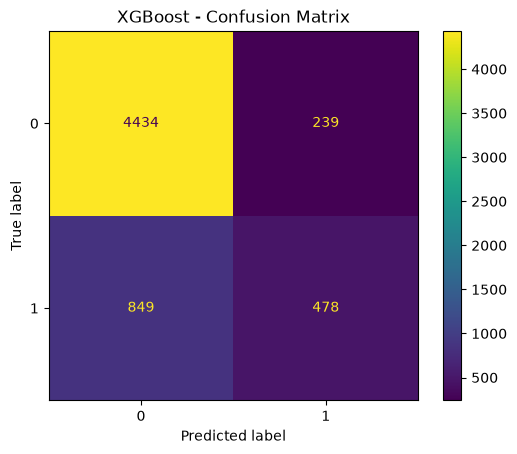

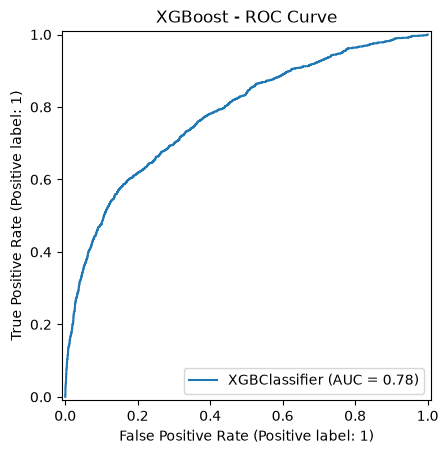

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

for name, model in best_models.items():

    predictions = model.predict(X_test_processed)

    # Confusion Matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions
    )
    plt.title(name + " - Confusion Matrix")
    plt.show()

    # ROC Curve
    RocCurveDisplay.from_estimator(
        model, X_test_processed, y_test
    )
    plt.title(name + " - ROC Curve")
    plt.show()

In [15]:
import joblib

champion = results_df.sort_values(
    by="ROC-AUC", ascending=False
).iloc[0]

print("Champion Model:", champion["Model"])
print("ROC-AUC:", champion["ROC-AUC"])

best_model = best_models[champion["Model"]]

joblib.dump(best_model, "champion_model.pkl")

print("Champion model saved successfully!")

Champion Model: XGBoost
ROC-AUC: 0.7789099657139871
Champion model saved successfully!
